<a href="https://colab.research.google.com/github/codewithsuprotim/Handwritten-Digit-Recognition/blob/main/Handwritten_Digit_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

# Load the 1,797 handwritten digit images
digits = load_digits()
images = digits.images  # Shape: (1797, 8, 8), values in [0, 16]
labels = digits.target  # Shape: (1797,), classes 0-9

print(f"Dataset Image Tensor Shape: {images.shape}")
print(f"Total Samples: {len(images)} | Classes: {np.unique(labels)}")
print("Samples per Digit Class:", dict(zip(*np.unique(labels, return_counts=True))))

Dataset Image Tensor Shape: (1797, 8, 8)
Total Samples: 1797 | Classes: [0 1 2 3 4 5 6 7 8 9]
Samples per Digit Class: {np.int64(0): np.int64(178), np.int64(1): np.int64(182), np.int64(2): np.int64(177), np.int64(3): np.int64(183), np.int64(4): np.int64(181), np.int64(5): np.int64(182), np.int64(6): np.int64(181), np.int64(7): np.int64(179), np.int64(8): np.int64(174), np.int64(9): np.int64(180)}


In [3]:
from skimage.feature import hog as skimage_hog

def extract_opencv_hog_features(image_batch: np.ndarray) -> tuple[np.ndarray, list[np.ndarray]]:
    """
    Applies OpenCV spatial preprocessing and computes HOG descriptors:
      1. Rescales 4-bit intensity [0, 16] to 8-bit grayscale [0, 255].
      2. Upsamples 8x8 -> 32x32 using bicubic interpolation so HOG 8x8 cells capture stroke geometry.
      3. Applies 3x3 Gaussian blur to suppress pixelation artifacts from upsampling.
      4. Extracts a 324-D L2-normalized Histogram of Oriented Gradients (HOG) vector.
    """
    feature_vectors = []
    preprocessed_samples = []

    for img in image_batch:
        # Step 1: Convert to uint8 [0, 255]
        img_uint8 = np.clip((img / 16.0) * 255.0, 0, 255).astype(np.uint8)

        # Step 2: OpenCV Bicubic Resize (8x8 -> 32x32)
        resized = cv2.resize(img_uint8, (32, 32), interpolation=cv2.INTER_CUBIC)

        # Step 3: OpenCV Gaussian Blur to smooth interpolation edges
        blurred = cv2.GaussianBlur(resized, (3, 3), sigmaX=0.8)

        # Step 4: Compute HOG feature descriptor using skimage.feature.hog
        # Configuration matches: 32x32 window, 16x16 block, 8x8 stride/cell, 9 bins -> 324 features
        descriptor = skimage_hog(
            blurred,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys',
            visualize=False
        )

        feature_vectors.append(descriptor)
        preprocessed_samples.append(blurred)

    return np.array(feature_vectors, dtype=np.float32), preprocessed_samples

# Extract HOG features for all 1,797 images
X_hog, processed_imgs = extract_opencv_hog_features(images)
y = labels

print(f"Extracted HOG Feature Matrix Shape: {X_hog.shape} (324 features per image)")

Extracted HOG Feature Matrix Shape: (1797, 324) (324 features per image)


In [4]:
# Stratified split (1,527 Train / 270 Test) preserving exact class balance
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X_hog, y, np.arange(len(y)), test_size=270, random_state=42, stratify=y
)

# Define models: RBF Kernel SVM (with feature scaling) vs. Random Forest
models = {
    "RBF SVM (C=5, gamma='scale')": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=5.0, gamma="scale", random_state=42)),
    ]),
    "Random Forest (300 trees)": RandomForestClassifier(
        n_estimators=300, max_features="sqrt", random_state=42, n_jobs=-1
    ),
}

benchmark_rows = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model

    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="macro")

    benchmark_rows.append({
        "Classifier": name,
        "Test Accuracy (%)": round(acc * 100, 2),
        "Macro Precision": round(prec, 4),
        "Macro Recall": round(rec, 4),
        "Macro F1-Score": round(f1, 4),
    })

results_df = pd.DataFrame(benchmark_rows)
print("=== Handwritten Digit Recognition Benchmark (1,797 Images | Test n=270) ===")
print(results_df.to_string(index=False))

svm_preds = trained_models["RBF SVM (C=5, gamma='scale')"].predict(X_test)
print("\n=== Detailed Classification Report: RBF SVM ===")
print(classification_report(y_test, svm_preds, digits=4))

=== Handwritten Digit Recognition Benchmark (1,797 Images | Test n=270) ===
                  Classifier  Test Accuracy (%)  Macro Precision  Macro Recall  Macro F1-Score
RBF SVM (C=5, gamma='scale')              98.89           0.9895        0.9887          0.9889
   Random Forest (300 trees)              97.78           0.9788        0.9774          0.9775

=== Detailed Classification Report: RBF SVM ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        27
           1     0.9310    1.0000    0.9643        27
           2     1.0000    1.0000    1.0000        27
           3     1.0000    1.0000    1.0000        28
           4     0.9643    1.0000    0.9818        27
           5     1.0000    1.0000    1.0000        27
           6     1.0000    0.9630    0.9811        27
           7     1.0000    1.0000    1.0000        27
           8     1.0000    0.9615    0.9804        26
           9     1.0000    0.9630    0.9811      

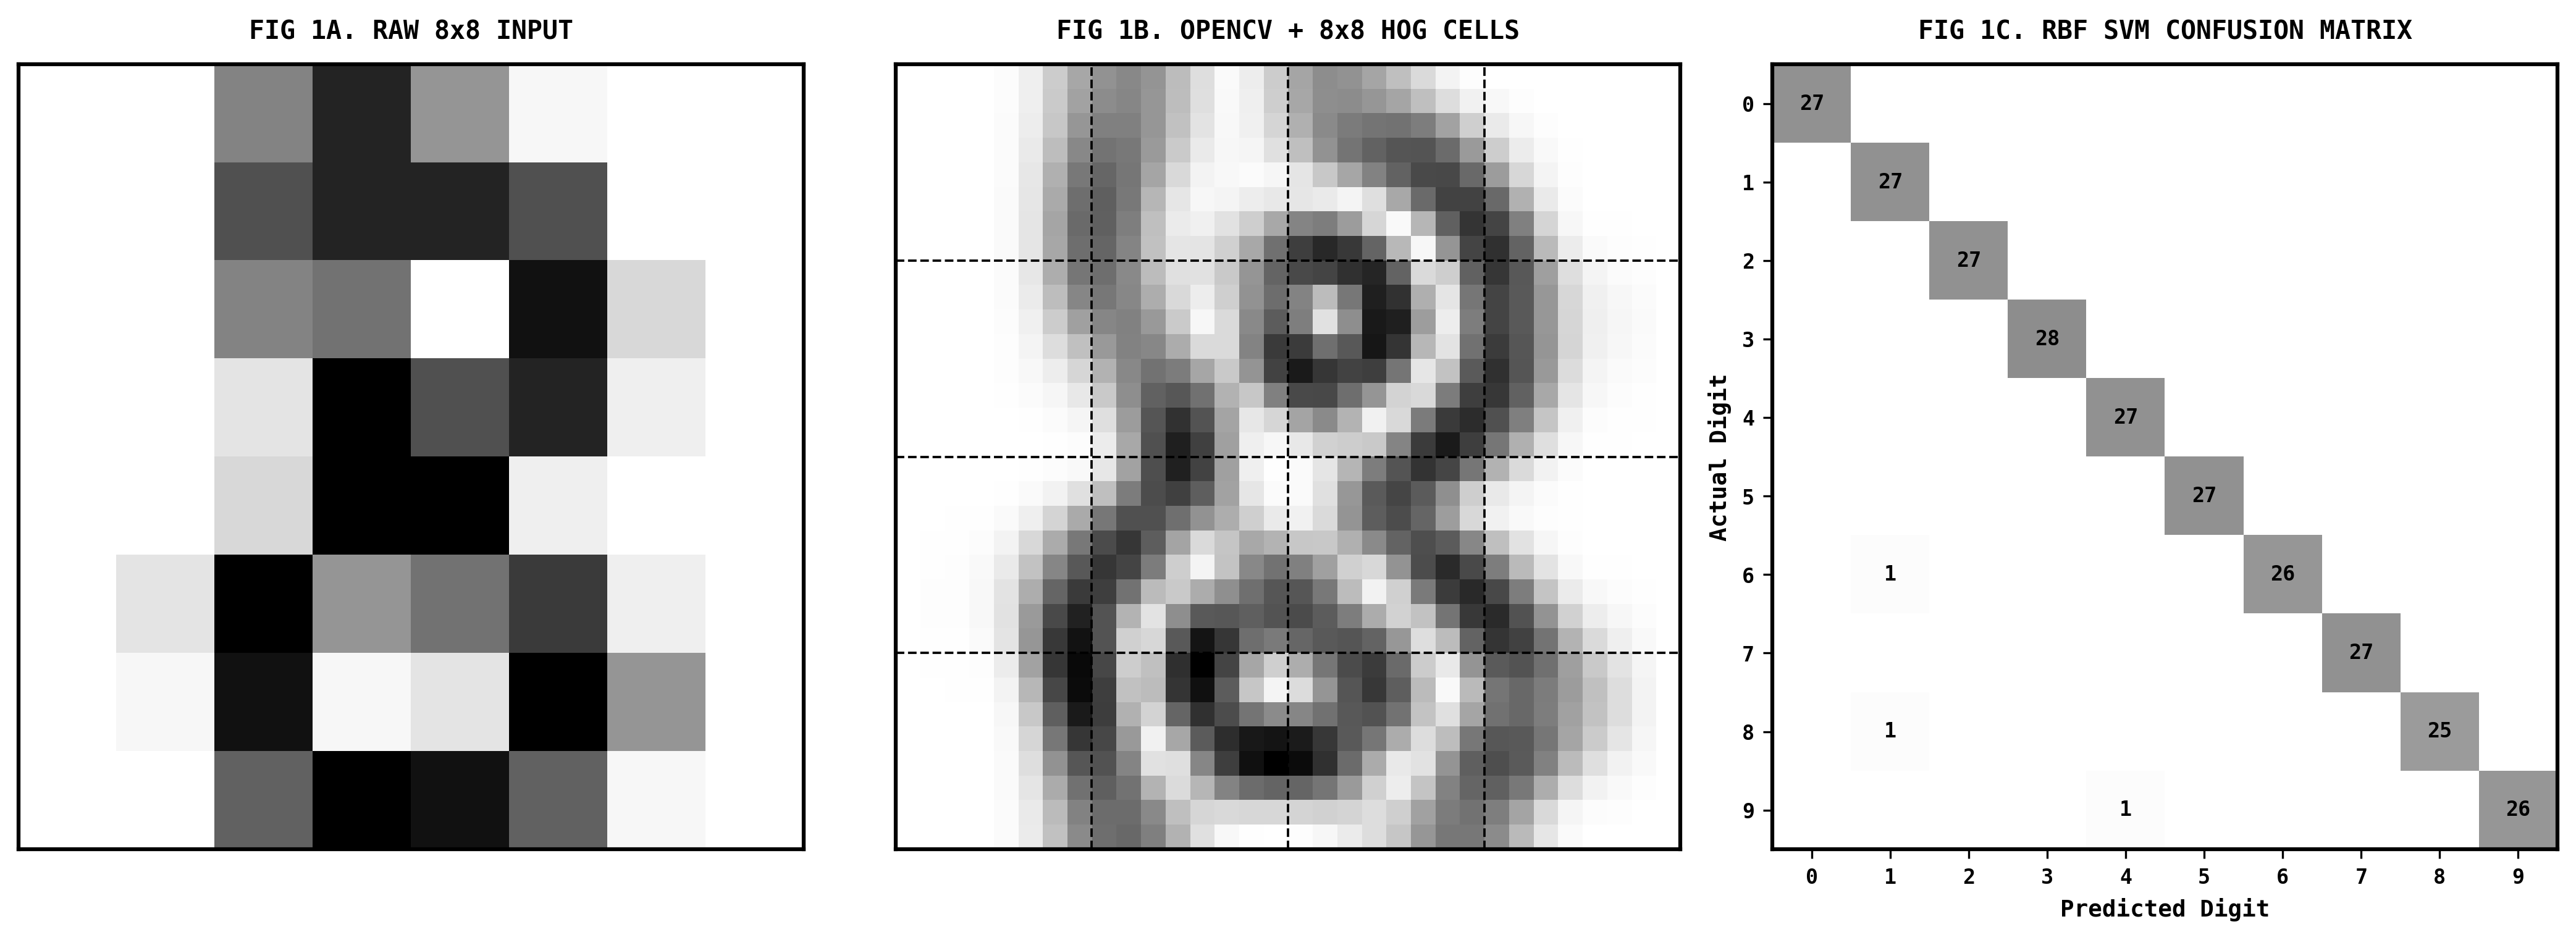

In [5]:
# Generates high-contrast monochrome (Black & White) technical figures saved to /content/
plt.rcParams["font.family"] = "monospace"

fig = plt.figure(figsize=(14, 5.5), dpi=300)
fig.patch.set_facecolor("white")

# --- Panel A: OpenCV Preprocessing & Gradient Magnitude Sketch (Digit '8') ---
sample_idx = 8
raw_8x8 = images[sample_idx]
proc_32x32 = processed_imgs[sample_idx]

# Compute Sobel X and Y gradients to sketch edge orientations
gx = cv2.Sobel(proc_32x32, cv2.CV_32F, 1, 0, ksize=1)
gy = cv2.Sobel(proc_32x32, cv2.CV_32F, 0, 1, ksize=1)
grad_mag = cv2.magnitude(gx, gy)

ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(raw_8x8, cmap="Greys", interpolation="nearest")
ax1.set_title("FIG 1A. RAW 8x8 INPUT", fontsize=10, fontweight="bold", pad=10)
ax1.set_xticks([])
ax1.set_yticks([])
for spine in ax1.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.5)

ax2 = fig.add_subplot(1, 3, 2)
ax2.imshow(grad_mag, cmap="Greys")
# Overlay 8x8 HOG cell grid in solid black
for pos in range(8, 32, 8):
    ax2.axhline(pos - 0.5, color="black", linestyle="--", linewidth=0.9)
    ax2.axvline(pos - 0.5, color="black", linestyle="--", linewidth=0.9)
ax2.set_title("FIG 1B. OPENCV + 8x8 HOG CELLS", fontsize=10, fontweight="bold", pad=10)
ax2.set_xticks([])
ax2.set_yticks([])
for spine in ax2.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.5)

# --- Panel C: Black & White 10x10 Confusion Matrix (RBF SVM) ---
ax3 = fig.add_subplot(1, 3, 3)
cm = confusion_matrix(y_test, svm_preds)
ax3.imshow(cm, cmap="Greys", alpha=0.45)
ax3.set_xticks(range(10))
ax3.set_yticks(range(10))
ax3.set_xticklabels(range(10), fontsize=8, fontweight="bold")
ax3.set_yticklabels(range(10), fontsize=8, fontweight="bold")
ax3.set_xlabel("Predicted Digit", fontsize=9, fontweight="bold")
ax3.set_ylabel("Actual Digit", fontsize=9, fontweight="bold")
ax3.set_title("FIG 1C. RBF SVM CONFUSION MATRIX", fontsize=10, fontweight="bold", pad=10)

for i in range(10):
    for j in range(10):
        if cm[i, j] > 0:
            ax3.text(
                j, i, str(cm[i, j]),
                ha="center", va="center", color="black", fontsize=8, fontweight="bold"
            )

for spine in ax3.spines.values():
    spine.set_edgecolor("black")
    spine.set_linewidth(1.5)

plt.tight_layout()
plt.savefig("/content/digit_recognition_bw_sketch.png", dpi=300, facecolor="white")
plt.show()

In [6]:
def predict_single_digit(image_array: np.ndarray) -> dict:
    """Runs OpenCV preprocessing + HOG + RBF SVM inference on a single grayscale digit image."""
    feats, _ = extract_opencv_hog_features(np.expand_dims(image_array, axis=0))
    svm_pipe = trained_models["RBF SVM (C=5, gamma='scale')"]
    pred_digit = int(svm_pipe.predict(feats)[0])
    return {"Predicted_Digit": pred_digit, "Feature_Dimensions": feats.shape[1]}

# Verify on 5 held-out test samples
for i in range(5):
    orig_idx = idx_test[i]
    res = predict_single_digit(images[orig_idx])
    print(f"Test Sample #{i+1} | Ground Truth: {y_test[i]} | Model Output: {res['Predicted_Digit']}")

Test Sample #1 | Ground Truth: 6 | Model Output: 6
Test Sample #2 | Ground Truth: 3 | Model Output: 3
Test Sample #3 | Ground Truth: 7 | Model Output: 7
Test Sample #4 | Ground Truth: 5 | Model Output: 5
Test Sample #5 | Ground Truth: 5 | Model Output: 5
